# FLIP: common-protocol comparison of image-conditional noise cGANs

**Question.** *How does the surrogate architecture used to train the trigger generator change the learned noise, and does it change FLIP's poisoning efficiency?*

Each trigger is an **image-conditional** perturbation δ(x) produced by a U-Net generator *G* from the truck image itself, added as x′ = x + δ(x). ‖δ‖∞ ≤ ε = 6/255 is enforced inside the generator (ε·tanh) and applied in 8-bit pixel units, so every method satisfies the bound exactly.

$$L_G = \lambda_{D}\,\mathrm{BCE}\big(D(x'),\ \text{clean}\big) + \lambda_{\text{sur}}\,\mathrm{CE}\big(s(x'),\ \text{deer}\big),\qquad \lambda_D = 2,\ \lambda_{\text{sur}} = 1$$

*D* is a discriminator that sees one image and says whether it was modified (SRM high-pass + spectrally normalised CNN), trained jointly with *G*; *s* is a frozen CIFAR-10 surrogate (seed 0). The generators are trained for 50 epochs on the 5,000 training trucks.

| Method | Surrogate *s* |
|---|---|
| cGAN–EfficientNet | EfficientNet-B0 |
| cGAN–R18 | ResNet-18 |
| cGAN–R32 | ResNet-32 |
| cGAN–NoSurrogate | none (λ_sur = 0): control |

**Shared FLIP protocol**
* CIFAR-10, source truck = 9 → target deer = 4.
* Expert: ResNet-32, 20 epochs, 5 experts pooled in trajectory matching (25 iterations), FLIP seed 0.
* Budgets: 300, 500, 1,000, 1,500 hard-label flips out of 50,000.
* Victim (user): ResNet-32, 100 epochs (lr ÷10 at epoch 75), 5 runs per budget; the same user seeds are used for every method (paired runs).

Scripts: `run_noise_cgan.py` (generators), `launch_cgan_flip.sh` → `run_full_flip.py` (FLIP), `plot_cgan_noise.py`.

In [1]:
from pathlib import Path
import sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPImage

start = Path.cwd().resolve()
ROOT = next((p for p in [start, *start.parents] if (p / 'run_experiment.py').is_file()), None)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from the FLIP repository (or a subfolder).')
sys.path[:0] = [str(ROOT), str(ROOT / 'modules')]
EXP = ROOT / 'experiments'; CGAN = ROOT / 'noise_generator/cgan'
FIG = ROOT / 'figures/cgan_common_analysis'
OUT = ROOT / 'results/cgan_common_analysis'
FIG.mkdir(parents=True, exist_ok=True); OUT.mkdir(parents=True, exist_ok=True)
BUDGETS = [300, 500, 1000, 1500]
EXPERTS = list(range(5)); RUNS_IDS = list(range(5)); SRC, TGT = 9, 4
USER_EPOCHS = 100
METHODS = {   # key = poisoner flag = generator name; FLIP experiment = flip_<key>
 'cgan_efficientnet': dict(label='cGAN–EfficientNet'),
 'cgan_resnet18':     dict(label='cGAN–R18'),
 'cgan_resnet32':     dict(label='cGAN–R32'),
 'cgan_nosurrogate':  dict(label='cGAN–NoSurrogate'),
}
REF = 'cgan_nosurrogate'      # control for paired differences
COLOR = dict(zip(METHODS, ['#2a78b5', '#d1603d', '#3d9a5b', '#7a7a7a']))
plt.rcParams.update({'figure.dpi':115, 'savefig.dpi':220, 'font.size':10,
                     'axes.spines.right':False,'axes.spines.top':False,
                     'axes.grid':True, 'grid.alpha':.17})

def save_figure(fig, basename):
    for ext in ('pdf', 'png'):
        fig.savefig(FIG/f'{basename}.{ext}', bbox_inches='tight', dpi=220)
    print('Saved figure:', basename)

def save_table(df, basename):
    df.to_csv(OUT/f'{basename}.csv', index=False)
    print('Saved table:', basename)

def exp_dir(v):
    return EXP/f'flip_{v}'

def load_run(v, b, r):
    d = exp_dir(v)/f'user_{b}'/str(r)
    a, bp = d/'caccs.npy', d/'paccs.npy'
    if not (a.is_file() and bp.is_file()): return None
    ca, pa = np.load(a, allow_pickle=False), np.load(bp, allow_pickle=False)
    if ca.ndim != 2 or pa.ndim != 2:
        raise ValueError(f'Unexpected metric shape: {d}: {ca.shape}, {pa.shape}')
    if len(ca) != USER_EPOCHS or len(pa) != USER_EPOCHS:
        warnings.warn(f'{d}: expected {USER_EPOCHS} evaluation epochs; found {len(ca)} and {len(pa)}')
    # caccs / paccs: one row per epoch, column 0 = accuracy in [0, 1], column 1 = loss.
    # PTA = fraction of triggered test trucks classified as deer.
    ccurve, pcurve = 100*ca[:, 0].astype(float), 100*pa[:, 0].astype(float)
    return dict(CTA=float(ccurve[-1]), PTA=float(pcurve[-1]), cta_curve=ccurve, pta_curve=pcurve)

print('Root:', ROOT); print('Figures:', FIG); print('Tables:', OUT)

Root: /Data/nadine.hc/FLIP
Figures: /Data/nadine.hc/FLIP/figures/cgan_common_analysis
Tables: /Data/nadine.hc/FLIP/results/cgan_common_analysis


## Inventory and per-run results

In [2]:
records = []; CURVES = {}
for v, m in METHODS.items():
    for b in BUDGETS:
        for r in RUNS_IDS:
            run = load_run(v, b, r)
            records.append(dict(variant=v, method=m['label'], budget=b, run=r, complete=run is not None,
                                CTA=np.nan if run is None else run['CTA'],
                                PTA=np.nan if run is None else run['PTA']))
            if run: CURVES[(v, b, r)] = run
RUNS = pd.DataFrame(records)
status = []
for v, m in METHODS.items():
    ck = ROOT/'out/checkpoints'/f'flip_{v}'
    experts = sum((ck/str(e)/'model_20_200.pth').is_file() for e in EXPERTS)
    labels = (exp_dir(v)/'labels.npy').is_file()
    flips = sum((exp_dir(v)/f'{b}.npy').is_file() for b in BUDGETS)
    victims = int(RUNS.loc[RUNS.variant.eq(v), 'complete'].sum())
    status.append(dict(method=m['label'], experts=f'{experts}/{len(EXPERTS)}', labels='yes' if labels else 'no',
                       flip_budgets=f'{flips}/{len(BUDGETS)}', victims=f'{victims}/{len(BUDGETS)*len(RUNS_IDS)}'))
STATUS = pd.DataFrame(status); display(STATUS)
READY = [v for v in METHODS if RUNS.loc[RUNS.variant.eq(v), 'complete'].all()]
print('Fully complete:', [METHODS[v]['label'] for v in READY])
save_table(STATUS, '00_completion_status'); save_table(RUNS, '01_victim_per_run')

AGG = (RUNS[RUNS.complete].groupby(['variant', 'method', 'budget'], sort=False)
       .agg(CTA_mean=('CTA', 'mean'), CTA_sd=('CTA', 'std'), PTA_mean=('PTA', 'mean'), PTA_sd=('PTA', 'std'),
            n=('run', 'size')).reset_index())
display(AGG.round(2)); save_table(AGG, '02_budget_mean_sd')

,method,experts,labels,flip_budgets,victims
0,cGAN–EfficientNet,5/5,yes,4/4,20/20
1,cGAN–R18,5/5,yes,4/4,20/20
2,cGAN–R32,5/5,yes,4/4,20/20
3,cGAN–NoSurrogate,5/5,yes,4/4,20/20


Fully complete: ['cGAN–EfficientNet', 'cGAN–R18', 'cGAN–R32', 'cGAN–NoSurrogate']
Saved table: 00_completion_status
Saved table: 01_victim_per_run


,variant,method,budget,CTA_mean,CTA_sd,PTA_mean,PTA_sd,n
0,cgan_efficientnet,cGAN–EfficientNet,300,91.63,0.16,72.30,4.73,5
1,cgan_efficientnet,cGAN–EfficientNet,500,91.31,0.36,82.44,3.12,5
2,cgan_efficientnet,cGAN–EfficientNet,1000,90.76,0.24,85.90,3.46,5
3,cgan_efficientnet,cGAN–EfficientNet,1500,89.75,0.61,91.70,1.00,5
4,cgan_resnet18,cGAN–R18,300,91.83,0.20,70.96,2.69,5
5,cgan_resnet18,cGAN–R18,500,91.70,0.29,74.38,5.07,5
6,cgan_resnet18,cGAN–R18,1000,90.75,0.46,85.04,2.34,5
7,cgan_resnet18,cGAN–R18,1500,90.14,0.27,89.54,1.77,5
8,cgan_resnet32,cGAN–R32,300,91.66,0.23,78.06,4.62,5
9,cgan_resnet32,cGAN–R32,500,91.33,0.13,84.90,2.24,5


Saved table: 02_budget_mean_sd


### Results table: final-epoch victim accuracy (mean ± SD over 5 victim runs, %)

In [3]:
if not AGG.empty:
    fmt = AGG.assign(CTA=AGG.CTA_mean.map('{:.2f}'.format) + ' ± ' + AGG.CTA_sd.map('{:.2f}'.format),
                     PTA=AGG.PTA_mean.map('{:.1f}'.format) + ' ± ' + AGG.PTA_sd.map('{:.1f}'.format))
    TABLE = (fmt.pivot(index='method', columns='budget', values=['PTA', 'CTA'])
             .reindex([m['label'] for m in METHODS.values()]))
    display(TABLE); TABLE.to_csv(OUT/'02b_results_table.csv'); print('Saved table: 02b_results_table')

PTA                                      \
budget                   300         500         1000        1500   
method                                                              
cGAN–EfficientNet  72.3 ± 4.7  82.4 ± 3.1  85.9 ± 3.5  91.7 ± 1.0   
cGAN–R18           71.0 ± 2.7  74.4 ± 5.1  85.0 ± 2.3  89.5 ± 1.8   
cGAN–R32           78.1 ± 4.6  84.9 ± 2.2  89.4 ± 1.9  91.5 ± 1.2   
cGAN–NoSurrogate    6.2 ± 1.7  10.4 ± 3.7  27.9 ± 4.7  36.4 ± 4.5   

                            CTA                                            
budget                     300           500           1000          1500  
method                                                                     
cGAN–EfficientNet  91.63 ± 0.16  91.31 ± 0.36  90.76 ± 0.24  89.75 ± 0.61  
cGAN–R18           91.83 ± 0.20  91.70 ± 0.29  90.75 ± 0.46  90.14 ± 0.27  
cGAN–R32           91.66 ± 0.23  91.33 ± 0.13  90.68 ± 0.17  89.96 ± 0.31  
cGAN–NoSurrogate   91.48 ± 0.28  91.07 ± 0.51  89.25 ± 0.40  88.15 ± 0.52

Saved table: 02b_results_table


## Generator training: losses across epochs

Saved figure: fig00_generator_losses


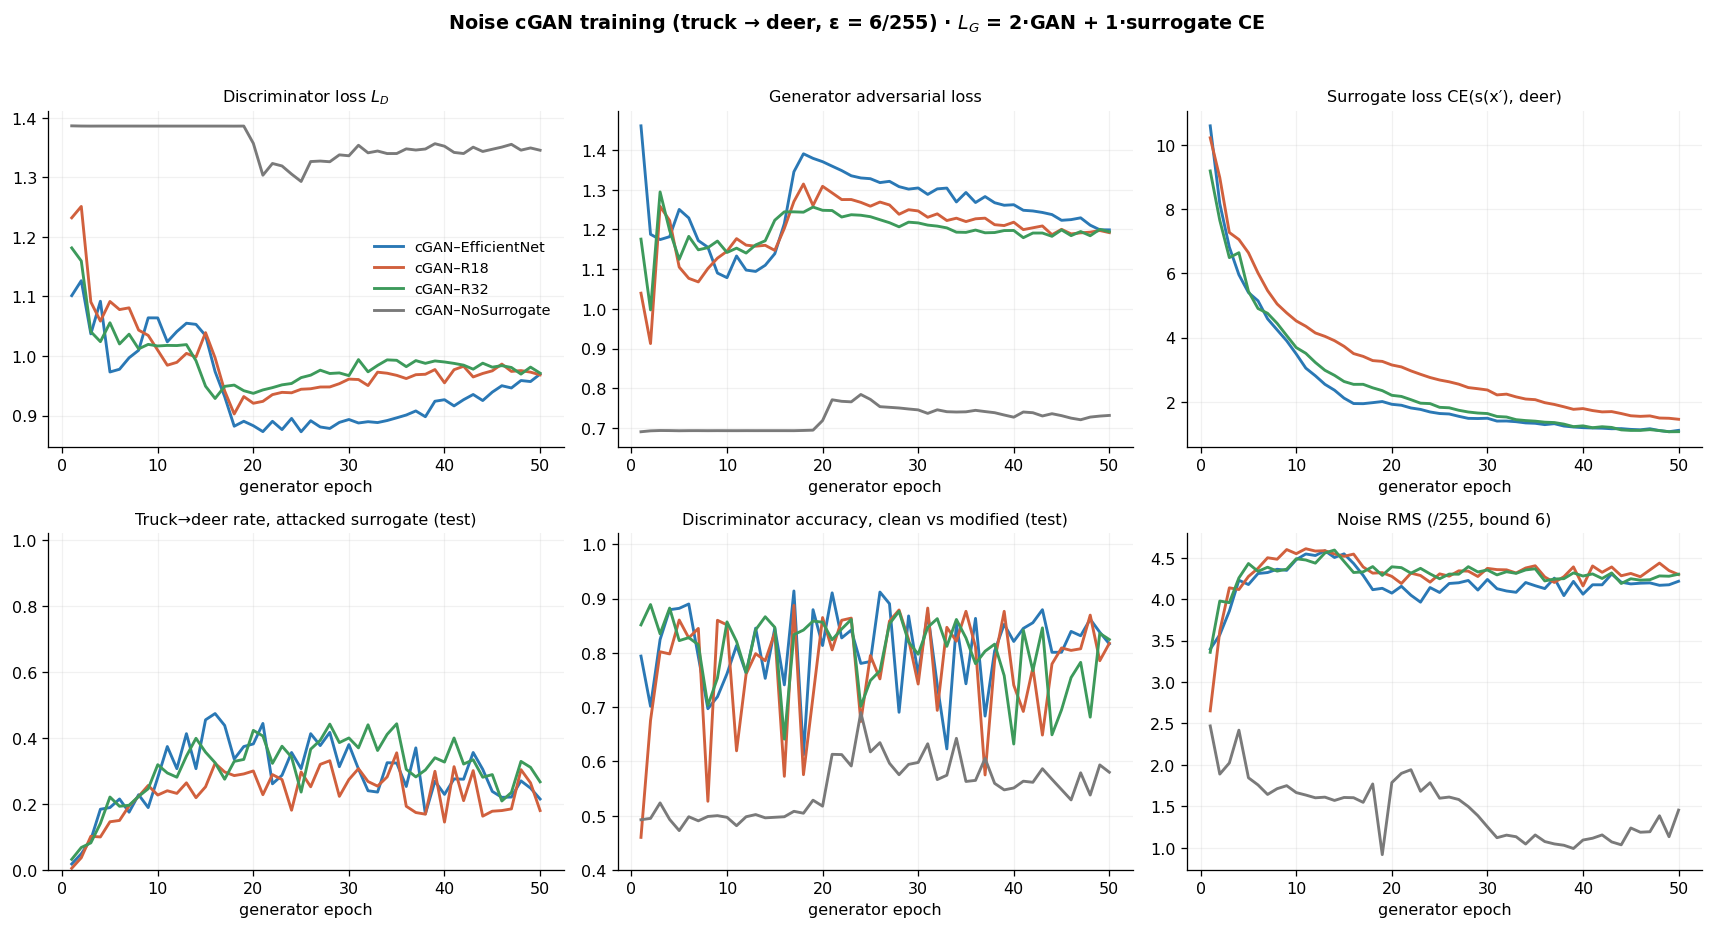

,method,d_loss,g_adv_loss,sur_loss,test_d_acc,deer_attacked,deer_heldout_resnet18,deer_heldout_resnet32,deer_heldout_efficientnet,rms_255,psnr
0,cGAN–EfficientNet,0.970,1.199,1.107,0.817,0.215,NaN,0.111,0.136,4.216,35.634
1,cGAN–R18,0.968,1.192,1.453,0.818,0.180,0.132,0.134,NaN,4.296,35.469
2,cGAN–R32,0.971,1.194,1.066,0.825,0.267,NaN,0.162,NaN,4.301,35.460
3,cGAN–NoSurrogate,1.346,0.732,NaN,0.580,NaN,NaN,0.001,NaN,1.453,44.885


Saved table: 03_generator_final_epoch


In [4]:
H = {v: json.load(open(CGAN/f'{v}.json'))['history'] for v in METHODS if (CGAN/f'{v}.json').is_file()}
panels = [('d_loss', 'Discriminator loss $L_D$', None),
          ('g_adv_loss', 'Generator adversarial loss', None),
          ('sur_loss', 'Surrogate loss CE(s(x′), deer)', None),
          ('deer_attacked', 'Truck→deer rate, attacked surrogate (test)', (0, 1.02)),
          ('test_d_acc', 'Discriminator accuracy, clean vs modified (test)', (0.4, 1.02)),
          ('rms_255', 'Noise RMS (/255, bound 6)', None)]
fig, axes = plt.subplots(2, 3, figsize=(15, 8.2))
for ax, (key, title, ylim) in zip(axes.flat, panels):
    for v, h in H.items():
        ys = [rec.get(key) for rec in h]
        if all(y is None for y in ys): continue
        ax.plot([rec['epoch'] for rec in h], ys, label=METHODS[v]['label'], color=COLOR[v], lw=1.8)
    ax.set_title(title, fontsize=10); ax.set_xlabel('generator epoch')
    if ylim: ax.set_ylim(*ylim)
axes[0, 0].legend(fontsize=9, frameon=False)
fig.suptitle('Noise cGAN training (truck → deer, ε = 6/255) · $L_G$ = 2·GAN + 1·surrogate CE', fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, .96)); save_figure(fig, 'fig00_generator_losses'); plt.show()

GEN = pd.DataFrame([dict(method=METHODS[v]['label'], **{k: h[-1].get(k) for k in
        ['d_loss', 'g_adv_loss', 'sur_loss', 'test_d_acc', 'deer_attacked', 'deer_heldout_resnet18',
         'deer_heldout_resnet32', 'deer_heldout_efficientnet', 'rms_255', 'psnr']}) for v, h in H.items()])
display(GEN.round(3)); save_table(GEN, '03_generator_final_epoch')

## CTA and PTA versus poisoning budget

Saved figure: fig01_cta_by_budget


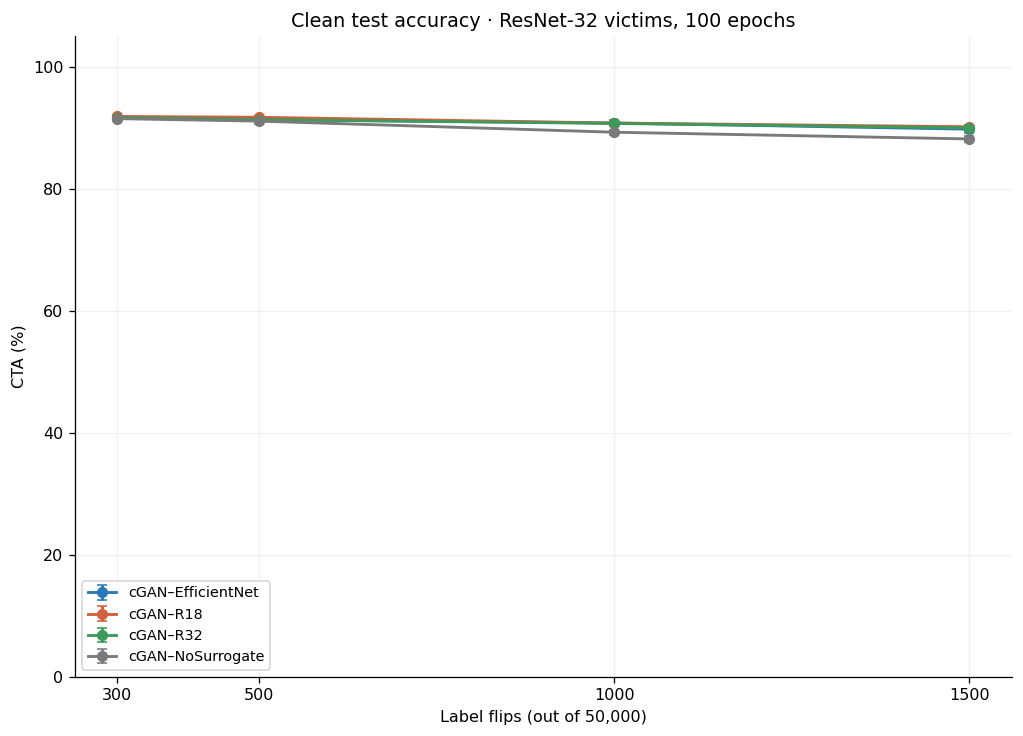

Saved figure: fig02_pta_by_budget


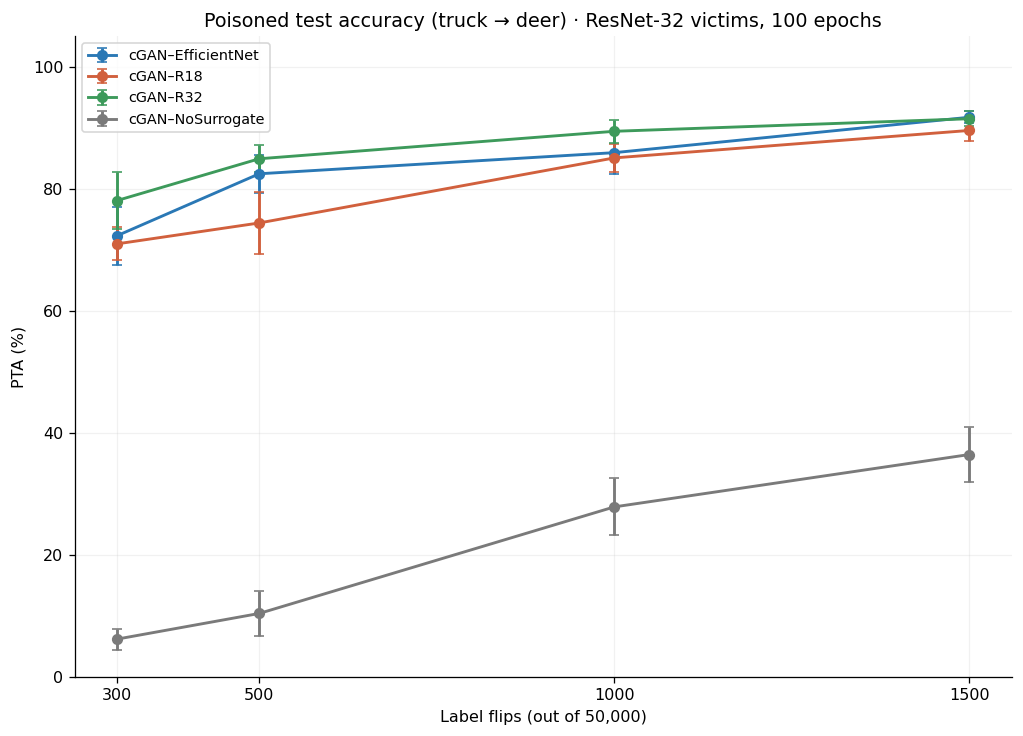

In [5]:
for metric, title, filename in [('CTA', 'Clean test accuracy', 'fig01_cta_by_budget'),
                                ('PTA', 'Poisoned test accuracy (truck → deer)', 'fig02_pta_by_budget')]:
    fig, ax = plt.subplots(figsize=(9, 6.5))
    for v in METHODS:
        sub = AGG[AGG.variant.eq(v)].sort_values('budget')
        if sub.empty: continue
        ax.errorbar(sub.budget, sub[f'{metric}_mean'], yerr=sub[f'{metric}_sd'].fillna(0),
                    label=METHODS[v]['label'], color=COLOR[v], marker='o', capsize=3, lw=1.8)
    ax.set_xticks(BUDGETS); ax.set_xlabel('Label flips (out of 50,000)'); ax.set_ylabel(f'{metric} (%)')
    ax.set_title(title + f' · ResNet-32 victims, {USER_EPOCHS} epochs')
    ax.set_ylim(0, 105); ax.legend(loc='best', fontsize=9)
    fig.tight_layout(); save_figure(fig, filename); plt.show()

## PTA and CTA during victim training

Saved figure: fig03_pta_by_epoch


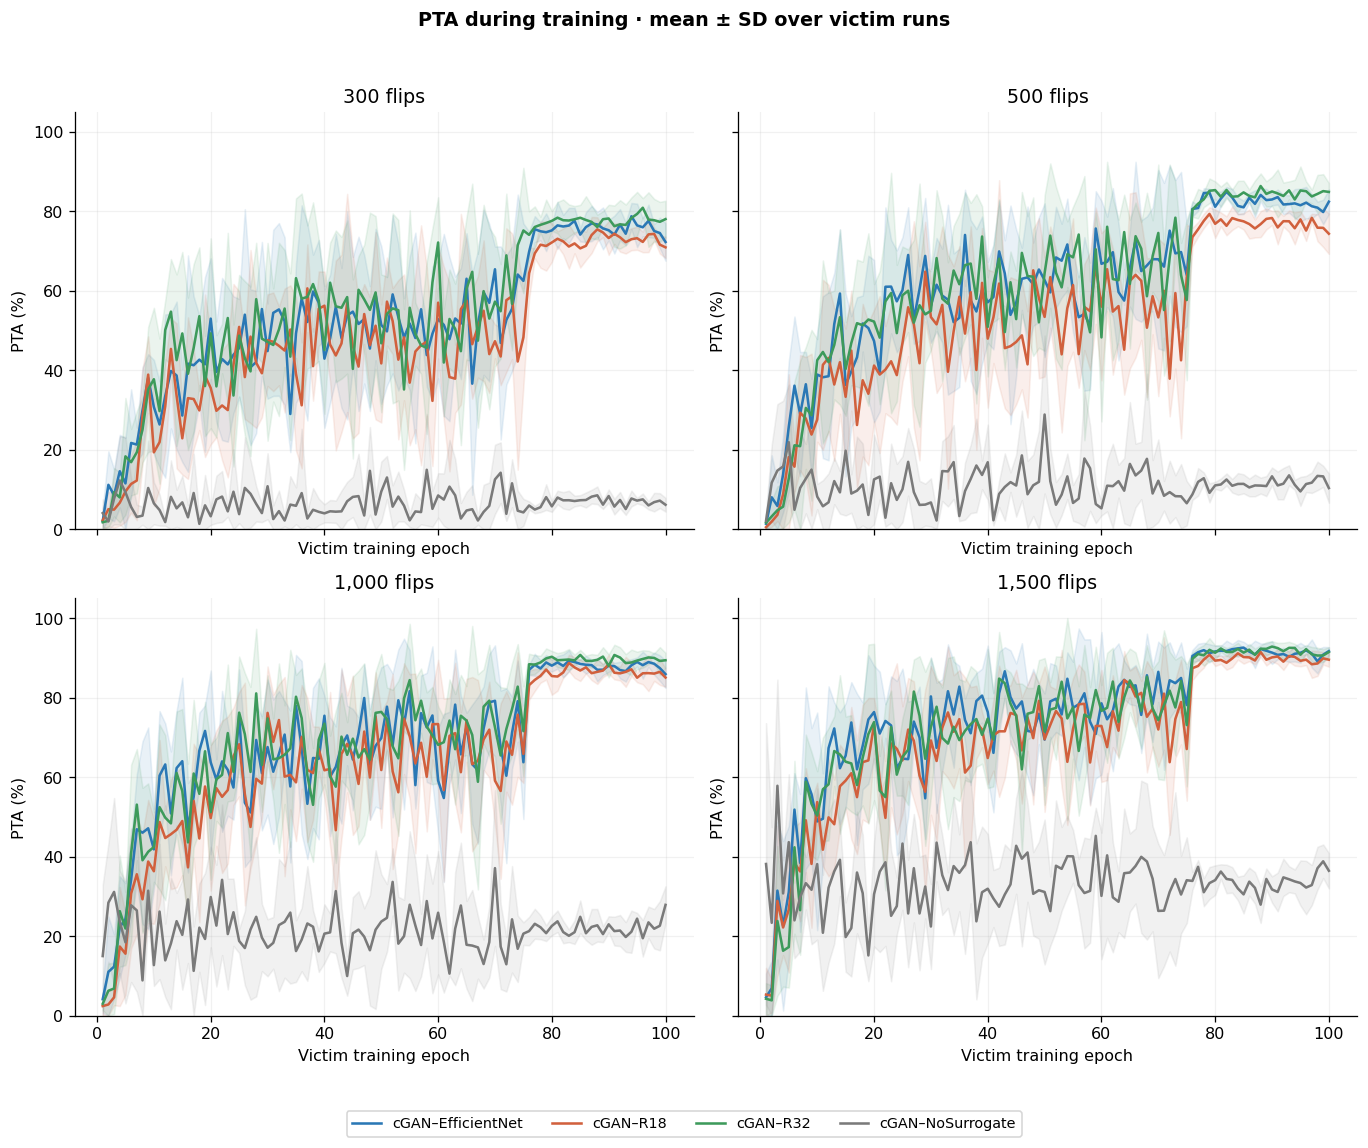

Saved figure: fig04_cta_by_epoch


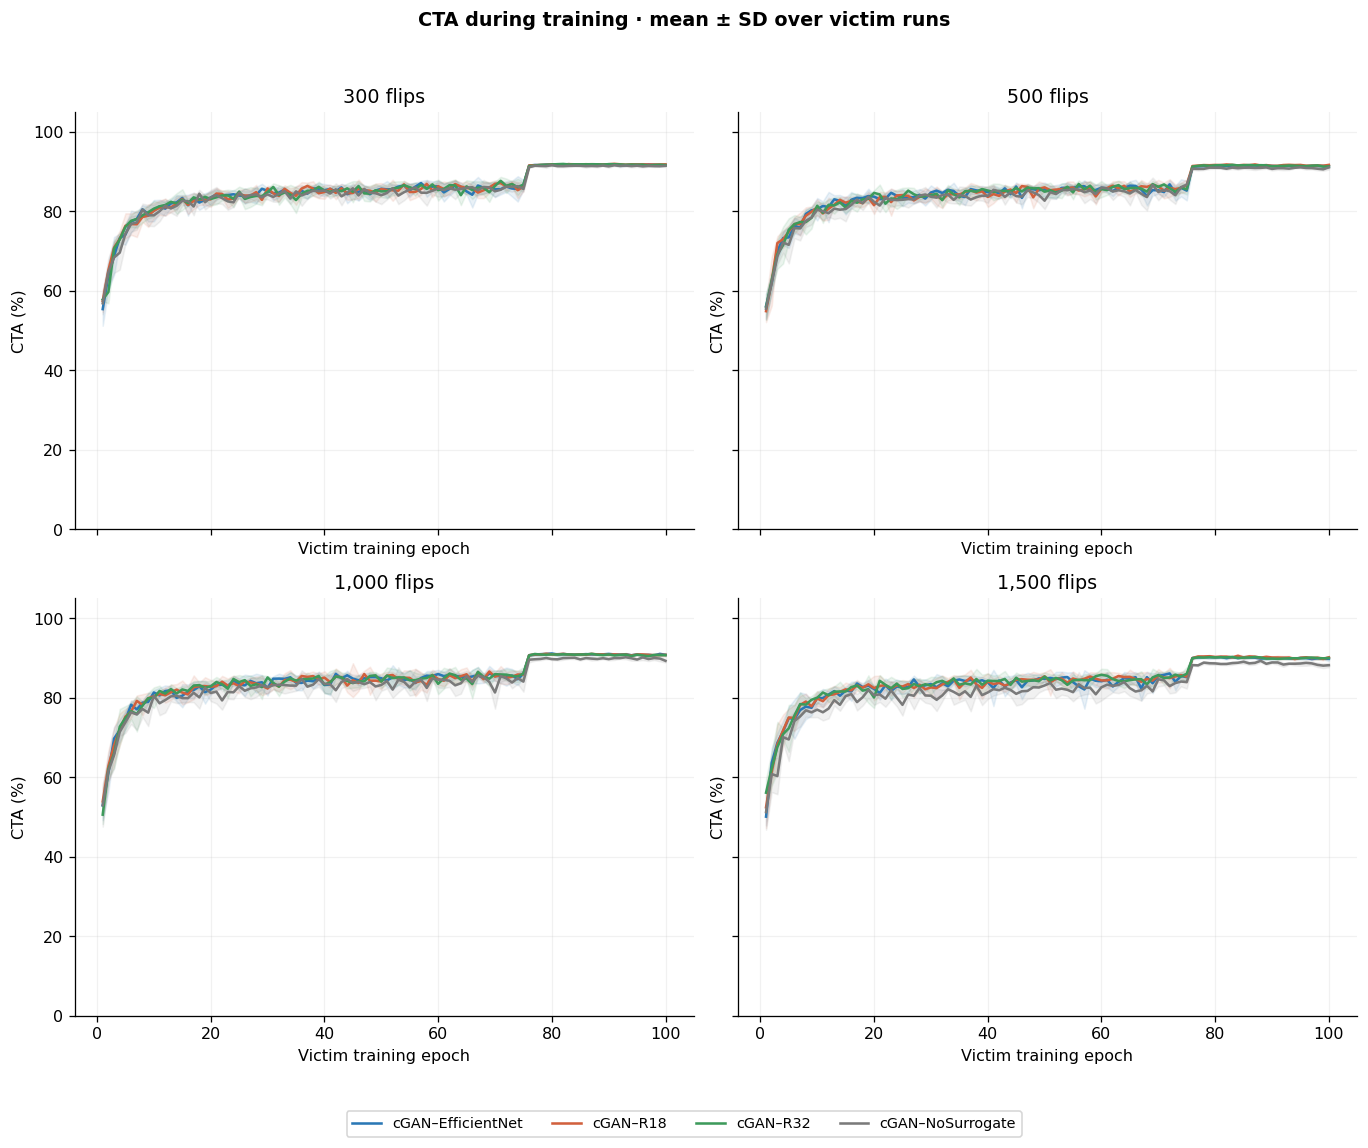

In [6]:
for metric in ('PTA', 'CTA'):
    fig, axes = plt.subplots(2, 2, figsize=(12, 10), sharex=True, sharey=True)
    for ax, b in zip(axes.flat, BUDGETS):
        for v in METHODS:
            arrs = [CURVES[(v, b, r)][metric.lower() + '_curve'] for r in RUNS_IDS if (v, b, r) in CURVES]
            if not arrs: continue
            length = min(map(len, arrs)); a = np.stack([x[:length] for x in arrs])
            x = np.arange(1, length + 1); mu = a.mean(0); sd = a.std(0, ddof=1) if len(a) > 1 else np.zeros(length)
            ax.plot(x, mu, label=METHODS[v]['label'], color=COLOR[v], lw=1.6)
            ax.fill_between(x, np.clip(mu - sd, 0, 100), np.clip(mu + sd, 0, 100), color=COLOR[v], alpha=.10)
        ax.set_title(f'{b:,} flips'); ax.set_ylim(0, 105)
        ax.set_xlabel('Victim training epoch'); ax.set_ylabel(f'{metric} (%)')
    handles, labels = axes.flat[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4, bbox_to_anchor=(.5, -.005), fontsize=9)
    fig.suptitle(f'{metric} during training · mean ± SD over victim runs', fontweight='bold')
    fig.tight_layout(rect=(0, .05, 1, .96))
    save_figure(fig, f'fig0{3 if metric == "PTA" else 4}_{metric.lower()}_by_epoch'); plt.show()

Saved figure: fig11_cta_barplot


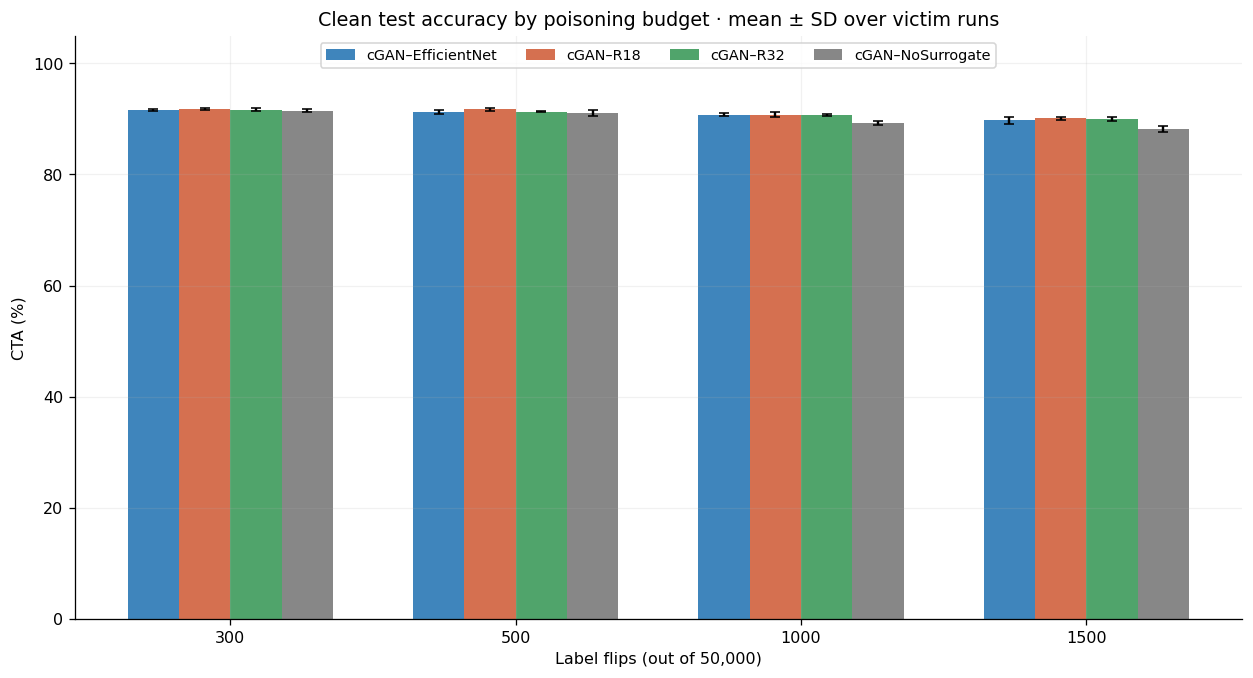

Saved figure: fig12_pta_barplot


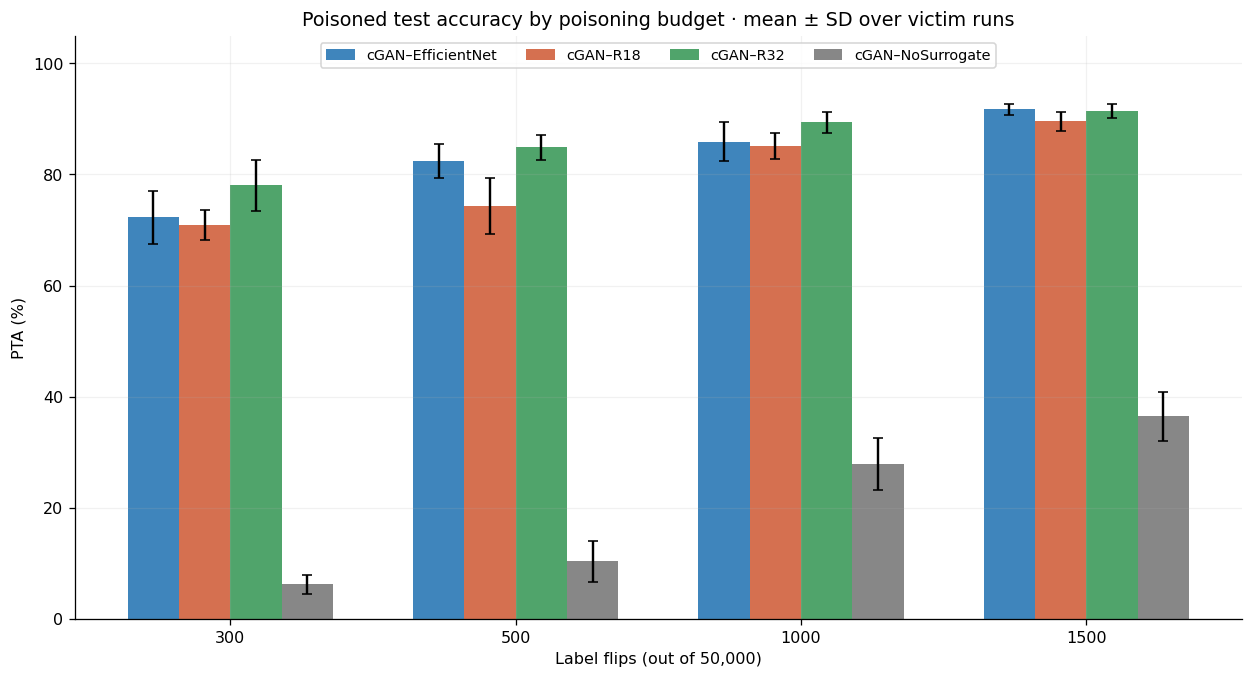

In [7]:
width = .18
for metric, title, filename in [('CTA', 'Clean test accuracy', 'fig11_cta_barplot'),
                                ('PTA', 'Poisoned test accuracy', 'fig12_pta_barplot')]:
    fig, ax = plt.subplots(figsize=(11, 6))
    x = np.arange(len(BUDGETS))
    for i, v in enumerate(METHODS):
        sub = AGG[AGG.variant.eq(v)].set_index('budget').reindex(BUDGETS)
        pos = x + (i - (len(METHODS) - 1) / 2) * width
        ax.bar(pos, sub[f'{metric}_mean'], width, yerr=sub[f'{metric}_sd'].fillna(0),
               label=METHODS[v]['label'], color=COLOR[v], capsize=3, alpha=.9)
    ax.set_xticks(x, BUDGETS)
    ax.set(xlabel='Label flips (out of 50,000)', ylabel=f'{metric} (%)',
           title=f'{title} by poisoning budget · mean ± SD over victim runs')
    ax.set_ylim(0, 105); ax.legend(ncol=4, fontsize=9, loc='upper center')
    fig.tight_layout(); save_figure(fig, filename); plt.show()

## CTA–PTA trade-off

Saved figure: fig05_cta_pta_tradeoff


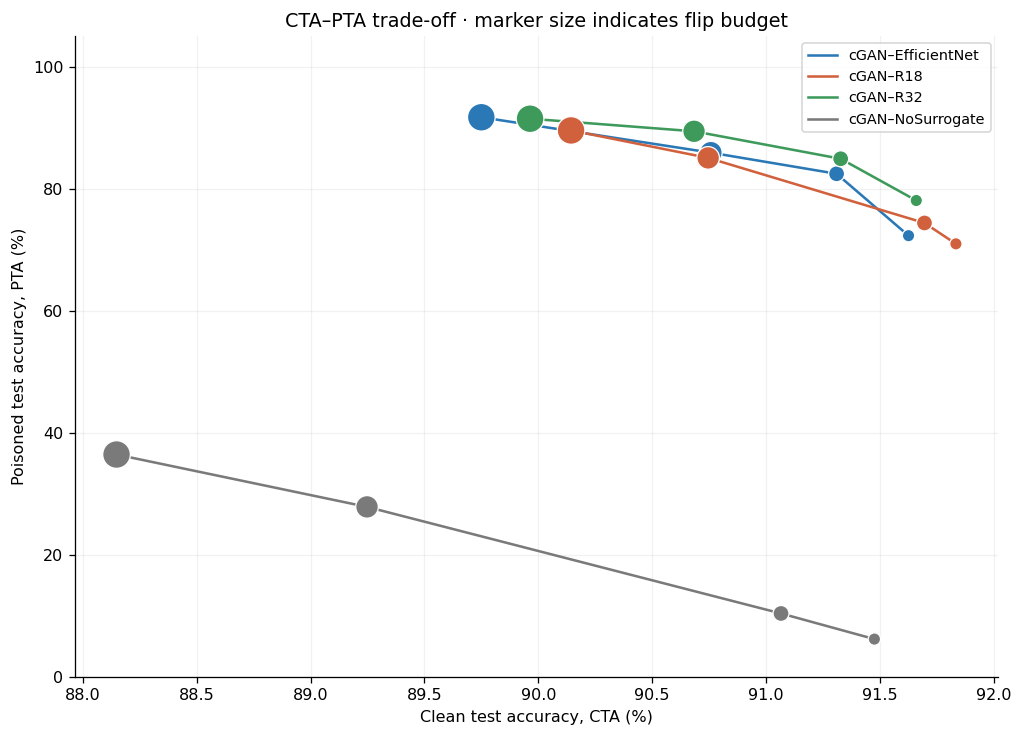

In [8]:
fig, ax = plt.subplots(figsize=(9, 6.5))
for v in METHODS:
    sub = AGG[AGG.variant.eq(v)].sort_values('budget')
    if sub.empty: continue
    ax.plot(sub.CTA_mean, sub.PTA_mean, '-', color=COLOR[v], lw=1.6, label=METHODS[v]['label'])
    ax.scatter(sub.CTA_mean, sub.PTA_mean, s=sub.budget / 5, color=COLOR[v], edgecolor='white', linewidth=.8, zorder=3)
ax.set(xlabel='Clean test accuracy, CTA (%)', ylabel='Poisoned test accuracy, PTA (%)', ylim=(0, 105),
       title='CTA–PTA trade-off · marker size indicates flip budget')
ax.legend(fontsize=9, loc='best')
fig.tight_layout(); save_figure(fig, 'fig05_cta_pta_tradeoff'); plt.show()

## Trigger images: clean truck, poisoned truck, signed noise

Noise is the exact 8-bit difference applied by the FLIP poisoner (`datasets.NoiseCGANPoisoner`), shown on a fixed scale for every method (gray = 0, saturated at ±6/255).

Noise cGAN poisoner (noise_generator/cgan/cgan_efficientnet.pth)
Noise cGAN poisoner (noise_generator/cgan/cgan_resnet18.pth)
Noise cGAN poisoner (noise_generator/cgan/cgan_resnet32.pth)
Noise cGAN poisoner (noise_generator/cgan/cgan_nosurrogate.pth)


,variant,method,Linf_px,RMS_px,mean_abs_px,saturated_frac,PSNR_dB
0,cgan_efficientnet,cGAN–EfficientNet,6,4.216,3.695,0.286,35.634
1,cgan_resnet18,cGAN–R18,6,4.296,3.777,0.319,35.469
2,cgan_resnet32,cGAN–R32,6,4.301,3.789,0.314,35.460
3,cgan_nosurrogate,cGAN–NoSurrogate,6,1.453,1.116,0.002,44.885


Saved table: 04_trigger_magnitude
Saved figure: fig06_images_and_noise


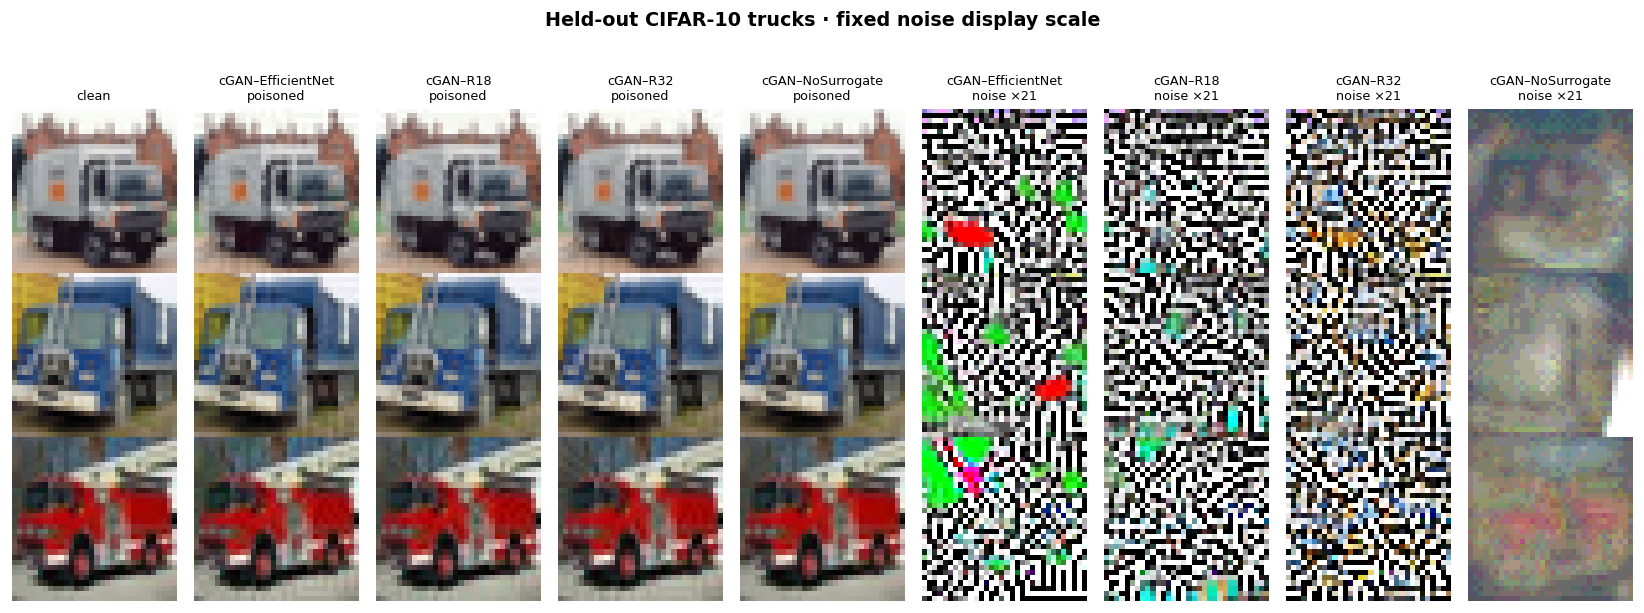

Saved figure: fig06b_mean_abs_noise


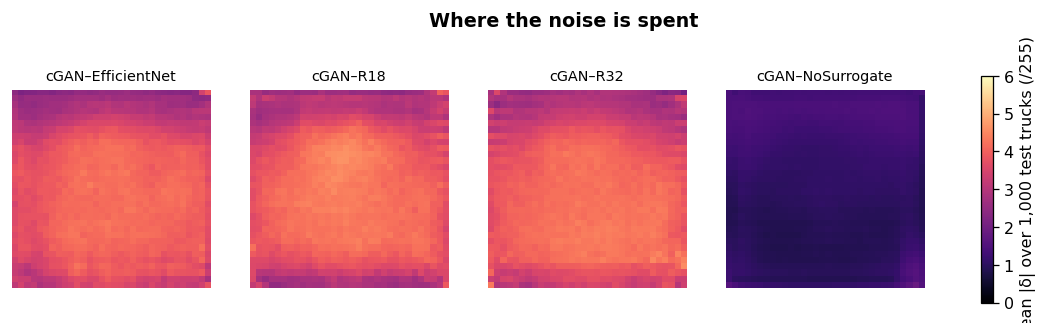

In [9]:
from torchvision.datasets import CIFAR10
from torchvision import transforms
from modules.base_utils.datasets import pick_poisoner

raw_test = CIFAR10(str(ROOT/'data/data_cifar10'), train=False, download=False)
truck_ids = [i for i, y in enumerate(raw_test.targets) if y == SRC]
truck_pils = [raw_test[i][0] for i in truck_ids]
clean_trucks = np.stack([np.asarray(im) for im in truck_pils]).astype(np.int16)
POISONERS, POISONED = {}, {}
for v in METHODS:
    if not (CGAN/f'{v}.pth').is_file(): print('missing generator', v); continue
    POISONERS[v] = pick_poisoner(v, 'cifar', TGT).poisoner
    POISONED[v] = np.stack([np.asarray(POISONERS[v](im)) for im in truck_pils]).astype(np.int16)

trig_stats = []
for v, xp in POISONED.items():
    d = xp - clean_trucks
    trig_stats.append(dict(variant=v, method=METHODS[v]['label'], Linf_px=int(np.abs(d).max()),
                           RMS_px=float(np.sqrt((d.astype(float)**2).mean())), mean_abs_px=float(np.abs(d).mean()),
                           saturated_frac=float((np.abs(d) == 6).mean()),
                           PSNR_dB=float(10*np.log10(255**2 / (d.astype(float)**2).mean()))))
TRIGGER = pd.DataFrame(trig_stats); display(TRIGGER.round(3)); save_table(TRIGGER, '04_trigger_magnitude')
assert (TRIGGER.Linf_px <= 6).all(), 'L_inf bound violated'

show = [0, 1, 2]
fig, axes = plt.subplots(len(show), 1 + 2*len(POISONED), figsize=(1.6*(1 + 2*len(POISONED)), 1.8*len(show)), squeeze=False)
for row, i in zip(axes, show):
    row[0].imshow(clean_trucks[i].astype('uint8')); row[0].set_title('clean' if i == show[0] else '', fontsize=8)
    for j, (v, xp) in enumerate(POISONED.items()):
        row[1 + j].imshow(xp[i].astype('uint8'))
        row[1 + len(POISONED) + j].imshow(np.clip((xp[i] - clean_trucks[i]) / 6 * 127.5 + 127.5, 0, 255).astype('uint8'))
        if i == show[0]:
            row[1 + j].set_title(METHODS[v]['label'] + '\npoisoned', fontsize=8)
            row[1 + len(POISONED) + j].set_title(METHODS[v]['label'] + '\nnoise ×21', fontsize=8)
for ax in axes.flat: ax.axis('off')
fig.suptitle('Held-out CIFAR-10 trucks · fixed noise display scale', fontweight='bold')
fig.tight_layout(rect=(0, 0, 1, .95)); save_figure(fig, 'fig06_images_and_noise'); plt.show()

fig, axes = plt.subplots(1, len(POISONED), figsize=(3.2*len(POISONED), 3.2), squeeze=False)
for ax, (v, xp) in zip(axes[0], POISONED.items()):
    im = ax.imshow(np.abs(xp - clean_trucks).mean((0, 3)), cmap='magma', vmin=0, vmax=6)
    ax.set_title(METHODS[v]['label'], fontsize=9); ax.axis('off')
fig.colorbar(im, ax=axes[0].tolist(), shrink=.8, label='mean |δ| over 1,000 test trucks (/255)')
fig.suptitle('Where the noise is spent', fontweight='bold'); save_figure(fig, 'fig06b_mean_abs_noise'); plt.show()

## Expert-model PTA / CTA

Final checkpoint (epoch 20) of each of the 5 experts per method, evaluated on the clean CIFAR-10 test set and on the 1,000 triggered test trucks.

In [10]:
import torch
from modules.base_utils.util import load_model
from modules.base_utils.datasets import CIFAR_TRANSFORM_NORMALIZE as normalize

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
to_tensor = transforms.ToTensor()
clean_inputs = torch.stack([to_tensor(x) for x, _ in raw_test])
clean_labels = torch.tensor(raw_test.targets, dtype=torch.long)

@torch.inference_mode()
def predictions(model, images, batch_size=500):
    return torch.cat([model(normalize(images[i:i + batch_size].to(DEVICE))).argmax(1).cpu()
                      for i in range(0, len(images), batch_size)])

expert_rows = []
for v, m in METHODS.items():
    if v not in POISONED: continue
    trig = torch.from_numpy(POISONED[v].astype(np.float32) / 255).permute(0, 3, 1, 2)
    for e in EXPERTS:
        ck = ROOT/'out/checkpoints'/f'flip_{v}'/str(e)/'model_20_200.pth'
        if not ck.is_file(): continue
        model = load_model('r32p', 10).to(DEVICE)
        model.load_state_dict(torch.load(ck, map_location=DEVICE)); model.eval()
        expert_rows.append(dict(variant=v, method=m['label'], expert=e,
                                Expert_CTA=100*(predictions(model, clean_inputs) == clean_labels).float().mean().item(),
                                Expert_PTA=100*(predictions(model, trig) == TGT).float().mean().item()))
        del model
EXPERT = pd.DataFrame(expert_rows)
if not EXPERT.empty:
    save_table(EXPERT, '05_expert_per_seed')
    expert_summary = (EXPERT.groupby(['variant', 'method'], sort=False)
                      .agg(PTA_mean=('Expert_PTA', 'mean'), PTA_sd=('Expert_PTA', 'std'),
                           CTA_mean=('Expert_CTA', 'mean'), CTA_sd=('Expert_CTA', 'std'), n=('expert', 'size')).reset_index())
    display(expert_summary.round(2)); save_table(expert_summary, '06_expert_summary')
else:
    print('No expert checkpoints found (remote results: ./launch_cgan_flip.sh --pull).')

Saved table: 05_expert_per_seed


,variant,method,PTA_mean,PTA_sd,CTA_mean,CTA_sd,n
0,cgan_efficientnet,cGAN–EfficientNet,90.26,7.97,83.59,0.98,5
1,cgan_resnet18,cGAN–R18,91.28,3.18,83.85,1.42,5
2,cgan_resnet32,cGAN–R32,90.40,4.27,83.74,1.77,5
3,cgan_nosurrogate,cGAN–NoSurrogate,52.18,44.16,78.77,4.41,5


Saved table: 06_expert_summary


## FLIP label solution: composition and overlap

**Composition**: which true labels are changed into which at each budget. **Overlap**: Jaccard similarity of the flipped indices between methods at the same budget.

n_flipped  truck→deer  truck→other  other→deer  \
method            budget                                                   
cGAN–EfficientNet 300           300         210           68          21   
                  500           500         283          152          63   
                  1000         1000         369          395         232   
                  1500         1500         420          624         447   
cGAN–R18          300           300         180           86          32   
                  500           500         243          180          73   
                  1000         1000         325          418         251   
                  1500         1500         368          651         473   
cGAN–R32          300           300         174           94          30   
                  500           500         232          195          66   
                  1000         1000         299          445         245   
                  1500         1500         338          673         473   
cGAN–NoSurrogate  300           300         300            0           0   
                  500           500         500            0           0   
                  1000         1000        1000            0           0   
                  1500         1500        1500            0           0   

                          other→other  
method            budget               
cGAN–EfficientNet 300               1  
                  500               2  
                  1000              4  
                  1500              9  
cGAN–R18          300               2  
                  500               4  
                  1000              6  
                  1500              8  
cGAN–R32          300               2  
                  500               7  
                  1000             11  
                  1500             16  
cGAN–NoSurrogate  300               0  
                  500               0  
                  1000              0  
                  1500              0

Saved table: 07_flip_composition
Saved figure: fig07_label_solution_composition


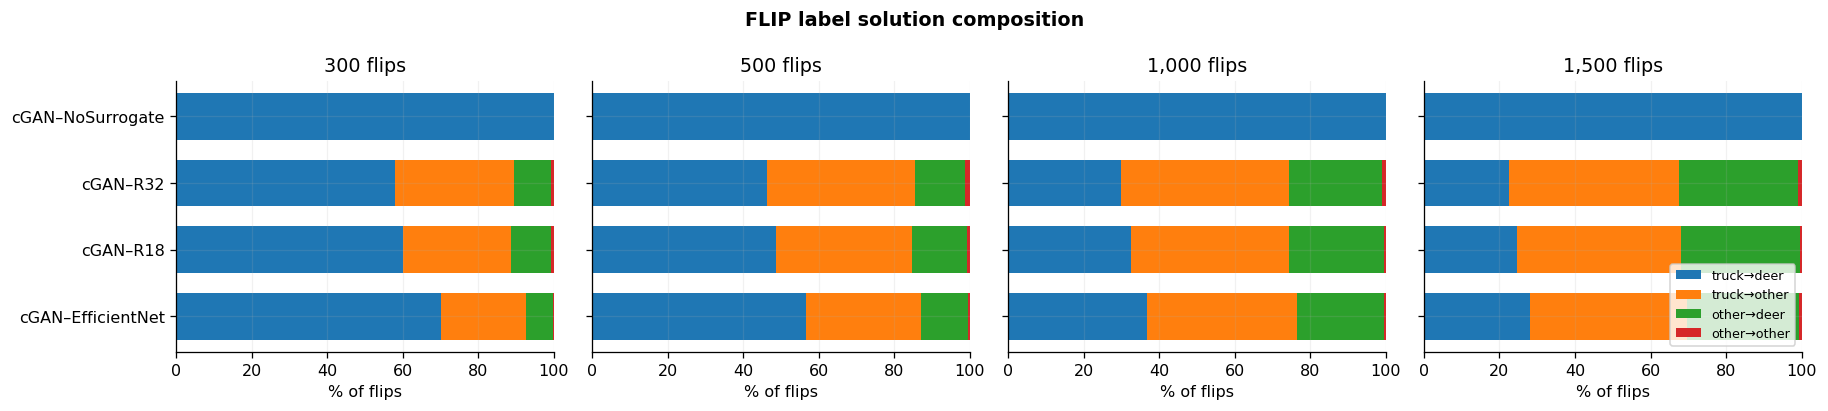

Saved figure: fig08_flip_overlap_jaccard


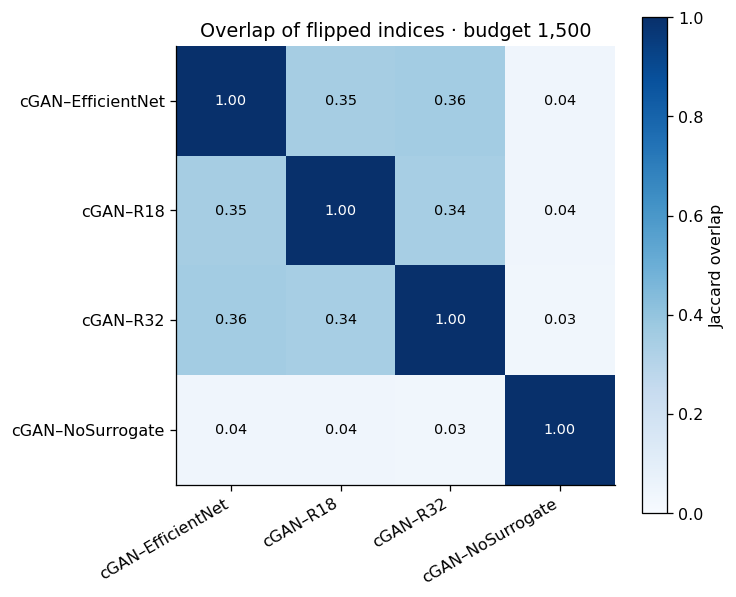

In [11]:
def labelvec(a):
    a = np.asarray(a)
    return a.argmax(axis=1) if a.ndim == 2 else a.astype(int).reshape(-1)
LABEL_DATA = {}; flip_rows = []
for v, m in METHODS.items():
    truth = exp_dir(v)/'true.npy'
    if not truth.is_file(): continue
    true = labelvec(np.load(truth))
    for b in BUDGETS:
        path = exp_dir(v)/f'{b}.npy'
        if not path.is_file(): continue
        pred = labelvec(np.load(path)); ix = np.flatnonzero(pred != true)
        LABEL_DATA[(v, b)] = set(ix.tolist())
        flip_rows.append(dict(variant=v, method=m['label'], budget=b, n_flipped=len(ix),
                              **{'truck→deer': int(np.sum((true[ix] == SRC) & (pred[ix] == TGT))),
                                 'truck→other': int(np.sum((true[ix] == SRC) & (pred[ix] != TGT))),
                                 'other→deer': int(np.sum((true[ix] != SRC) & (pred[ix] == TGT))),
                                 'other→other': int(np.sum((true[ix] != SRC) & (pred[ix] != TGT)))}))
FLIPS = pd.DataFrame(flip_rows)
if not FLIPS.empty:
    display(FLIPS.set_index(['method', 'budget']).drop(columns='variant')); save_table(FLIPS, '07_flip_composition')
    cats = ['truck→deer', 'truck→other', 'other→deer', 'other→other']
    fig, axes = plt.subplots(1, len(BUDGETS), figsize=(4*len(BUDGETS), 3.6), sharey=True)
    present = [v for v in METHODS if FLIPS.variant.eq(v).any()]
    for ax, b in zip(axes, BUDGETS):
        sub = FLIPS[FLIPS.budget.eq(b)].set_index('variant').reindex(present); left = np.zeros(len(present))
        for cat in cats:
            vals = (100*sub[cat]/sub['n_flipped'].clip(lower=1)).fillna(0).to_numpy()
            ax.barh(range(len(present)), vals, left=left, label=cat, height=.7); left += vals
        ax.set_yticks(range(len(present)), [METHODS[v]['label'] for v in present]); ax.invert_yaxis()
        ax.set_xlim(0, 100); ax.set_title(f'{b:,} flips'); ax.set_xlabel('% of flips')
    axes[-1].legend(fontsize=8, loc='lower right'); fig.suptitle('FLIP label solution composition', fontweight='bold')
    fig.tight_layout(); save_figure(fig, 'fig07_label_solution_composition'); plt.show()

    for b in [1500]:
        pres = [v for v in METHODS if (v, b) in LABEL_DATA]
        jacc = np.array([[len(LABEL_DATA[(v, b)] & LABEL_DATA[(w, b)]) / max(1, len(LABEL_DATA[(v, b)] | LABEL_DATA[(w, b)]))
                          for w in pres] for v in pres])
        fig, ax = plt.subplots(figsize=(6.5, 5.5)); im = ax.imshow(jacc, vmin=0, vmax=1, cmap='Blues')
        for (i, j), x in np.ndenumerate(jacc):
            ax.text(j, i, f'{x:.2f}', ha='center', va='center', fontsize=9, color='white' if x > .55 else 'black')
        ax.set_xticks(range(len(pres)), [METHODS[v]['label'] for v in pres], rotation=30, ha='right')
        ax.set_yticks(range(len(pres)), [METHODS[v]['label'] for v in pres]); ax.grid(False)
        fig.colorbar(im, ax=ax, label='Jaccard overlap'); ax.set_title(f'Overlap of flipped indices · budget {b:,}')
        fig.tight_layout(); save_figure(fig, 'fig08_flip_overlap_jaccard'); plt.show()
else:
    print('No FLIP labels yet.')

## Paired differences vs the no-surrogate control

Every method uses the same user seeds (`--user-seed 100000`), so run *r* at budget *b* is paired across methods. Differences are in percentage points (method − cGAN–NoSurrogate).

,method,budget,delta_PTA_mean,delta_PTA_sd,delta_CTA_mean,delta_CTA_sd,n
0,cGAN–EfficientNet,300,66.10,3.21,0.15,0.28,5
1,cGAN–R18,300,64.76,4.22,0.36,0.30,5
2,cGAN–R32,300,71.86,5.05,0.18,0.44,5
3,cGAN–EfficientNet,500,72.04,4.83,0.24,0.63,5
4,cGAN–R18,500,63.98,6.30,0.63,0.56,5
5,cGAN–R32,500,74.50,4.52,0.26,0.41,5
6,cGAN–EfficientNet,1000,58.04,6.62,1.51,0.34,5
7,cGAN–R18,1000,57.18,3.68,1.50,0.35,5
8,cGAN–R32,1000,61.54,4.15,1.44,0.40,5
9,cGAN–EfficientNet,1500,55.26,3.59,1.60,0.51,5


Saved table: 08_paired_vs_nosurrogate
Saved figure: fig09_paired_pta_difference


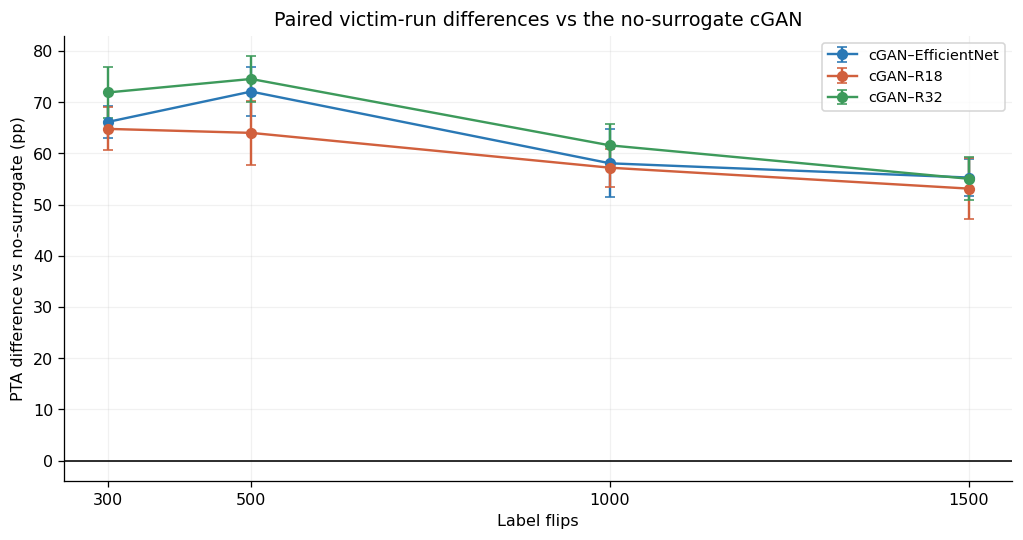

In [12]:
base = RUNS[RUNS.complete & RUNS.variant.eq(REF)][['budget', 'run', 'CTA', 'PTA']].rename(
    columns={'CTA': 'CTA_ref', 'PTA': 'PTA_ref'})
if not base.empty:
    D = RUNS[RUNS.complete & ~RUNS.variant.eq(REF)].merge(base, on=['budget', 'run'], validate='many_to_one')
    for metric in ('CTA', 'PTA'): D[f'delta_{metric}_pp'] = D[metric] - D[f'{metric}_ref']
    dsummary = (D.groupby(['method', 'budget'], sort=False)
                .agg(delta_PTA_mean=('delta_PTA_pp', 'mean'), delta_PTA_sd=('delta_PTA_pp', 'std'),
                     delta_CTA_mean=('delta_CTA_pp', 'mean'), delta_CTA_sd=('delta_CTA_pp', 'std'), n=('run', 'size')).reset_index())
    display(dsummary.round(2)); save_table(dsummary, '08_paired_vs_nosurrogate')
    fig, ax = plt.subplots(figsize=(9, 4.8))
    for v in METHODS:
        if v == REF: continue
        sub = D[D.variant.eq(v)].groupby('budget')['delta_PTA_pp'].agg(['mean', 'std']).reindex(BUDGETS)
        if sub['mean'].notna().any():
            ax.errorbar(BUDGETS, sub['mean'], yerr=sub['std'].fillna(0), fmt='o-', capsize=3, color=COLOR[v], label=METHODS[v]['label'])
    ax.axhline(0, color='black', lw=1); ax.set_xticks(BUDGETS)
    ax.set(xlabel='Label flips', ylabel='PTA difference vs no-surrogate (pp)', title='Paired victim-run differences vs the no-surrogate cGAN')
    ax.legend(fontsize=9); fig.tight_layout(); save_figure(fig, 'fig09_paired_pta_difference'); plt.show()
else:
    print('Control runs not available yet.')

## Trigger energy vs attack strength

The no-surrogate generator has no incentive to use its ε budget, so its noise is much weaker (lower RMS) than the surrogate-driven ones: differences against it mix *what* the noise encodes with *how much* noise there is.

Saved figure: fig10_trigger_rms


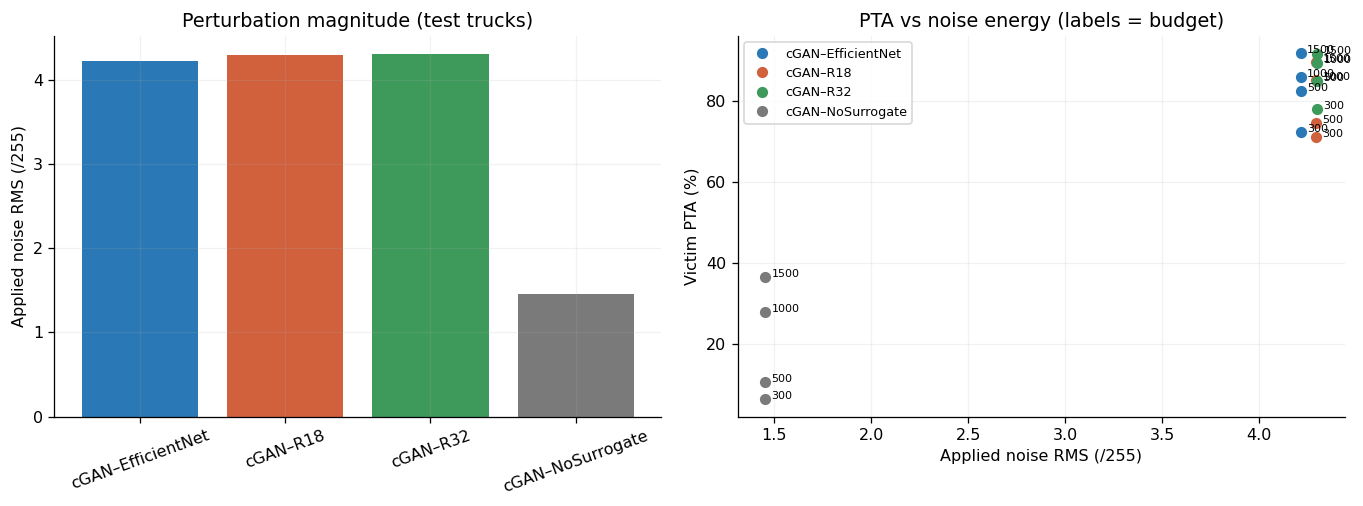

In [13]:
if not TRIGGER.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].bar(TRIGGER.method, TRIGGER.RMS_px, color=[COLOR[v] for v in TRIGGER.variant])
    axes[0].set(ylabel='Applied noise RMS (/255)', title='Perturbation magnitude (test trucks)')
    axes[0].tick_params(axis='x', rotation=20)
    if not AGG.empty:
        for v in METHODS:
            sub = AGG[AGG.variant.eq(v)].sort_values('budget'); t = TRIGGER[TRIGGER.variant.eq(v)]
            if sub.empty or t.empty: continue
            axes[1].plot([t.RMS_px.iloc[0]]*len(sub), sub.PTA_mean, 'o', color=COLOR[v], label=METHODS[v]['label'])
            for _, r in sub.iterrows():
                axes[1].annotate(f"{int(r.budget)}", (t.RMS_px.iloc[0], r.PTA_mean), fontsize=7, xytext=(4, 0), textcoords='offset points')
        axes[1].set(xlabel='Applied noise RMS (/255)', ylabel='Victim PTA (%)', title='PTA vs noise energy (labels = budget)')
        axes[1].legend(fontsize=8)
    fig.tight_layout(); save_figure(fig, 'fig10_trigger_rms'); plt.show()